<a href="https://colab.research.google.com/github/yhnx/EN4554_Assignment_2/blob/main/Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 – Assignment 2: CNNs (CIFAR-10, PyTorch)

**Name:** `Asuramuni S. Y.`  **Index No.:** `220046R`  
**GitHub:** `https://github.com/yhnx/EN4554_Assignment_2`

**AI-tool acknowledgement:** *I used Claude's help in drafting some code snippets of this notebook to assist with the implementation and debugging. I have read, run and understood all of the code, and the interpretations are my own.*



## 0. Setup, data and shared utilities

In [1]:
import os, math, time, random, copy
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torch.optim import Optimizer
from IPython.display import display


SEED = 42


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.backends.cudnn.benchmark = True
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('device:', device, '| torch', torch.__version__)

device: cpu | torch 2.11.0+cpu


In [ ]:
# # ---- Load CIFAR-10, split 45k/5k, normalise with TRAIN statistics ----
# def load_cifar10(root='./data'):
#     tr = torchvision.datasets.CIFAR10(root, train=True,  download=True)
#     te = torchvision.datasets.CIFAR10(root, train=False, download=True)
#     f = lambda a: torch.from_numpy(a).permute(0, 3, 1, 2).contiguous()      # uint8, N x 3 x 32 x 32
#     return f(tr.data), torch.tensor(tr.targets), f(te.data), torch.tensor(te.targets)

# CLASSES = ['plane','car','bird','cat','deer','dog','frog','horse','ship','truck']
# X_all, Y_all, X_te, Y_te = load_cifar10()

# g = torch.Generator().manual_seed(SEED)
# perm = torch.randperm(len(X_all), generator=g)
# tr_idx, va_idx = perm[:45000], perm[45000:]

# # 1. Send the entire raw uint8 tensor to the GPU immediately
# X_all_gpu = X_all.to(device)
# Y_all_gpu = Y_all.to(device)
# X_te_gpu = X_te.to(device)
# Y_te_gpu = Y_te.to(device)

# # 2. Extract indices on the GPU and cast to float once
# Xtr_raw = X_all_gpu[tr_idx].float() / 255.0

# # 3. Calculate statistics instantly using GPU parallelization
# MEAN = Xtr_raw.mean((0, 2, 3), keepdim=True)          # computed instantly on GPU
# STD  = Xtr_raw.std((0, 2, 3), keepdim=True)
# norm = lambda x: (x.float() / 255.0 - MEAN) / STD

# # 4. Final splits are already on the GPU
# Xtr, Ytr = norm(X_all_gpu[tr_idx]), Y_all_gpu[tr_idx]
# Xva, Yva = norm(X_all_gpu[va_idx]), Y_all_gpu[va_idx]
# Xte, Yte = norm(X_te_gpu), Y_te_gpu

# # Clean up temporary GPU raw reference
# del Xtr_raw
# print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape), '| mean', MEAN.flatten().tolist(), '| std', STD.flatten().tolist())

# # 5. Plotting (Move only the 16 display samples back to CPU)
# fig, axs = plt.subplots(2, 8, figsize=(12, 3.4))
# for a, i in zip(axs.flat, range(16)):
#     # Pulling specific images to CPU only when needed for matplotlib
#     img = (Xtr[i] * MEAN.new_tensor(STD.flatten())[:, None, None] + MEAN.new_tensor(MEAN.flatten())[:, None, None]).clamp(0, 1).cpu().permute(1, 2, 0)
#     a.imshow(img); a.set_title(CLASSES[Ytr[i].item()], fontsize=8); a.axis('off')
# plt.tight_layout(); plt.show()


100%|██████████| 170M/170M [1:03:28<00:00, 44.8kB/s]


train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | mean [0.49165481328964233, 0.4823332130908966, 0.4466792047023773] | std [0.24708116054534912, 0.2435086965560913, 0.2615806758403778]


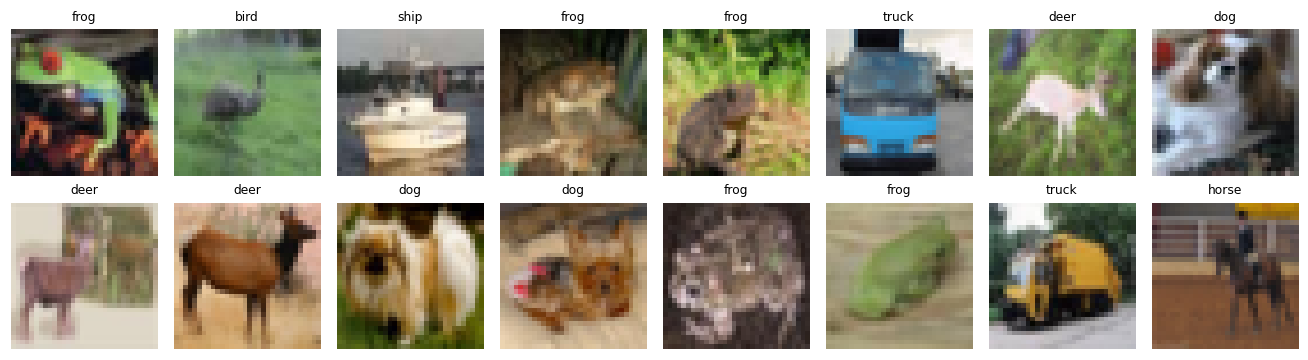

In [2]:
# ---- Load CIFAR-10, split 45k/5k, normalise with TRAIN statistics ----
def load_cifar10(root='./data'):
    tr = torchvision.datasets.CIFAR10(root, train=True,  download=True)
    te = torchvision.datasets.CIFAR10(root, train=False, download=True)
    f = lambda a: torch.from_numpy(a).permute(0, 3, 1, 2).contiguous()      # uint8, N x 3 x 32 x 32
    return f(tr.data), torch.tensor(tr.targets), f(te.data), torch.tensor(te.targets)

CLASSES = ['plane','car','bird','cat','deer','dog','frog','horse','ship','truck']
X_all, Y_all, X_te, Y_te = load_cifar10()

g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(X_all), generator=g)
tr_idx, va_idx = perm[:45000], perm[45000:]

x01 = X_all[tr_idx].float() / 255
MEAN = x01.mean((0, 2, 3), keepdim=True)          # statistics from the training split only
STD  = x01.std((0, 2, 3), keepdim=True)
norm = lambda x: (x.float() / 255 - MEAN) / STD

Xtr, Ytr = norm(X_all[tr_idx]).to(device), Y_all[tr_idx].to(device)
Xva, Yva = norm(X_all[va_idx]).to(device), Y_all[va_idx].to(device)
Xte, Yte = norm(X_te), Y_te
del x01
print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape), '| mean', MEAN.flatten().tolist(), '| std', STD.flatten().tolist())

fig, axs = plt.subplots(2, 8, figsize=(12, 3.4))
for a, i in zip(axs.flat, range(16)):
    img = (Xtr[i].cpu() * STD[0] + MEAN[0]).clamp(0, 1).permute(1, 2, 0)
    a.imshow(img); a.set_title(CLASSES[Ytr[i].item()], fontsize=8); a.axis('off')
plt.tight_layout(); plt.show()

In [3]:
# ---- Shared utilities: evaluation, GPU augmentations, training loop ----
def amp_ctx(on):
    return torch.autocast(device_type=device, dtype=torch.float16, enabled=(on and device == 'cuda'))

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, X, Y, bs=1000, amp=False):
    model.eval(); loss, correct = 0., 0
    for i in range(0, len(X), bs):
        with amp_ctx(amp):
            out = model(X[i:i+bs])
        loss += F.cross_entropy(out.float(), Y[i:i+bs], reduction='sum').item()
        correct += (out.argmax(1) == Y[i:i+bs]).sum().item()
    return loss / len(X), correct / len(X)

def random_flip_crop(x, pad=4):
    """Random horizontal flip + random 32x32 crop from the zero-padded image (per-sample, vectorised)."""
    N, C, H, W = x.shape; d = x.device
    flip = torch.rand(N, device=d) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    oy = torch.randint(0, 2 * pad + 1, (N,), device=d); ox = torch.randint(0, 2 * pad + 1, (N,), device=d)
    ar = torch.arange(H, device=d)
    rows = (oy[:, None] + ar)[:, None, :, None]
    cols = (ox[:, None] + ar)[:, None, None, :]
    n = torch.arange(N, device=d)[:, None, None, None]; c = torch.arange(C, device=d)[None, :, None, None]
    return xp[n, c, rows, cols]

def cutout(x, size=16):
    """Cutout: zero (= the mean colour after normalisation) a size x size square at a random centre; may be clipped at borders."""
    N, C, H, W = x.shape; d = x.device
    cy = torch.randint(0, H, (N, 1), device=d); cx = torch.randint(0, W, (N, 1), device=d)
    ar = torch.arange(H, device=d)[None]
    my = (ar >= cy - size // 2) & (ar < cy + size // 2)
    mx = (ar >= cx - size // 2) & (ar < cx + size // 2)
    mask = (my[:, :, None] & mx[:, None, :])[:, None]
    return x.masked_fill(mask, 0.)

def mixup_batch(x, y, alpha=0.4):
    """Mixup: x~ = lam*x_i + (1-lam)*x_j, lam ~ Beta(alpha, alpha). Loss = lam*CE(y_i) + (1-lam)*CE(y_j)."""
    lam = float(np.random.beta(alpha, alpha))
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam

def warmup_cosine(opt, total_steps, warmup_steps):
    def f(s):
        if s < warmup_steps: return (s + 1) / warmup_steps
        p = (s - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * p))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def train(model, opt, X, Y, Xv, Yv, epochs, bs=128, flipcrop=False, cut=False, mix=False,
          sched=None, label_smoothing=0.0, amp=False, eval_train=False, verbose=True, name=''):
    """Generic training loop. Returns history dict. If eval_train, train accuracy is measured on the clean
    (un-augmented) training set in eval mode; otherwise it is the running accuracy during the epoch."""
    scaler = torch.amp.GradScaler(device, enabled=(amp and device == 'cuda'))
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc']}; hist['diverged'] = False
    nb = max(1, len(X) // bs)
    for e in range(epochs):
        model.train(); t0 = time.time()
        perm = torch.randperm(len(X), device=X.device)
        run_loss = torch.zeros((), device=X.device); run_corr = torch.zeros((), device=X.device); seen = 0
        for b in range(nb):
            idx = perm[b * bs:(b + 1) * bs]
            xb, yb = X[idx], Y[idx]
            if flipcrop: xb = random_flip_crop(xb)
            if cut:      xb = cutout(xb)
            with amp_ctx(amp):
                if mix:
                    xb, ya, yb2, lam = mixup_batch(xb, yb)
                    out = model(xb)
                    loss = lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing) \
                         + (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=label_smoothing)
                    tgt = ya
                else:
                    out = model(xb); loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing); tgt = yb
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sched is not None: sched.step()
            run_loss += loss.detach() * len(idx); run_corr += (out.argmax(1) == tgt).sum(); seen += len(idx)
        tl = (run_loss / seen).item()
        if not math.isfinite(tl):                       # training blew up
            hist['diverged'] = True
            hist['train_loss'].append(float('nan')); hist['train_acc'].append(0.1)
            hist['val_loss'].append(float('nan')); hist['val_acc'].append(0.1)
            if verbose: print(f'{name} epoch {e+1}: DIVERGED');
            break
        vl, va = evaluate(model, Xv, Yv, amp=amp)
        ta = evaluate(model, X, Y, amp=amp)[1] if eval_train else (run_corr / seen).item()
        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [tl, ta, vl, va]): hist[k].append(v)
        if verbose and (e % max(1, epochs // 10) == 0 or e == epochs - 1):
            print(f'{name} ep {e+1:3d}/{epochs} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.1f}s')
    return hist

---
# Task 1: Backpropagation

## (a) Layers with explicit forward / backward (no autograd)


In [5]:
# Used claude to teach me the steps

class Linear:
    def __init__(self, din, dout, dtype=torch.float32, device='cpu'):
        self.W = torch.randn(din, dout, dtype=dtype, device=device) / math.sqrt(din)
        self.b = torch.zeros(dout, dtype=dtype, device=device)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, g):
        self.dW = self.x.T @ g
        self.db = g.sum(0)
        return g @ self.W.T

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, g):
        return g * self.mask

class Sigmoid:
    def forward(self, x):
        self.y = torch.sigmoid(x)
        return self.y
    def backward(self, g):
        return g * self.y * (1 - self.y)

class SoftmaxCE:
    def forward(self, logits, y):
        z = logits - logits.max(1, keepdim=True).values            # numerical stability
        logp = z - torch.logsumexp(z, 1, keepdim=True)
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y)), y].mean()
    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y)), self.y] -= 1
        return g / len(self.y)

class MLP:
    def __init__(self, sizes, act='relu', dtype=torch.float32, device='cpu'):
      self.layers = []
      for i in range(len(sizes) - 1):
          self.layers.append(Linear(sizes[i], sizes[i + 1], dtype, device))
          if i < len(sizes) - 2:
              self.layers.append(ReLU() if act == 'relu' else Sigmoid())
      self.loss_fn = SoftmaxCE()
    def forward(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)
    def backward(self):
        g = self.loss_fn.backward()
        for l in reversed(self.layers): g = l.backward(g)
    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

## (b) Gradient check: autograd and centred finite differences


In [ ]:
def autograd_grads(mlp, x, y):
    """Same network re-implemented with autograd (copies of the same weights)."""
    P = []
    for L in mlp.linears():
        P += [L.W.clone().requires_grad_(True), L.b.clone().requires_grad_(True)]
    h, n = x, len(mlp.linears())
    for i in range(n):
        h = h @ P[2 * i] + P[2 * i + 1]
        if i < n - 1: h = torch.relu(h)
    loss = F.cross_entropy(h, y); loss.backward()
    return loss.item(), [p.grad for p in P]

relerr = lambda a, b: ((a - b).norm() / (a.norm() + b.norm() + 1e-300)).item()

set_seed()
chk = MLP([3072, 64, 32, 10], act='relu', dtype=torch.float64, device='cpu')
xc, yc = Xtr[:32].flatten(1).double().cpu(), Ytr[:32].cpu()
loss_mine = chk.loss(xc, yc).item(); chk.backward()
loss_ag, g_ag = autograd_grads(chk, xc, yc)
print(f'loss (mine) {loss_mine:.10f} | loss (autograd) {loss_ag:.10f}')

names  = [f'{k}{i+1}' for i in range(len(chk.linears())) for k in ('W', 'b')]
g_mine = [t for L in chk.linears() for t in (L.dW, L.db)]
params = [t for L in chk.linears() for t in (L.W, L.b)]
EPS, rows = 1e-6, []
for nm, gm, ga, P in zip(names, g_mine, g_ag, params):
    sel = [tuple(int(i) for i in np.unravel_index(int(k), P.shape)) for k in torch.randperm(P.numel())[:10]]
    fd, an = [], []
    for ix in sel:
        old = P[ix].item()
        P[ix] = old + EPS; lp = chk.loss(xc, yc).item()
        P[ix] = old - EPS; lm = chk.loss(xc, yc).item()
        P[ix] = old
        fd.append((lp - lm) / (2 * EPS)); an.append(gm[ix].item())
    fd, an = torch.tensor(fd, dtype=torch.float64), torch.tensor(an, dtype=torch.float64)
    rows.append({'param': nm, 'rel.err vs autograd': relerr(gm, ga),
                 'allclose vs autograd': torch.allclose(gm, ga, rtol=1e-6, atol=1e-10),
                 'rel.err vs finite-diff': relerr(an, fd),
                 'allclose vs finite-diff': torch.allclose(an, fd, rtol=1e-4, atol=1e-7)})
display(pd.DataFrame(rows).style.format({'rel.err vs autograd': '{:.2e}', 'rel.err vs finite-diff': '{:.2e}'}))

loss (mine) 3.0925811666 | loss (autograd) 3.0925811666


,param,rel.err vs autograd,allclose vs autograd,rel.err vs finite-diff,allclose vs finite-diff
0,W1,8.05e-17,True,6.57e-09,True
1,b1,7.36e-17,True,2.31e-09,True
2,W2,5.80e-17,True,1.54e-09,True
3,b2,9.22e-17,True,2.03e-09,True
4,W3,6.22e-17,True,4.44e-10,True
5,b3,2.56e-17,True,9.48e-10,True


Compared to autograd, the value differences are in the order of $\sim10^{-15}$–$10^{-12}$, which is expected due to the round-off errors of float64 operations.

Compared to the finite difference formulae, the relative error differences are in the range of $\sim10^{-8}$–$10^{-6}$, which is relatively higher than autograd but again expected, as finite difference calculations have inherent numerical errors due to truncation $O(\epsilon^2)$ and round-off $O(u/\epsilon)$\.

Both checks pass, which means the backward formulae are correct.

## 1(c) Training (with our custom backprop)


epoch  1 | train acc 0.498 | val acc 0.461
epoch  2 | train acc 0.558 | val acc 0.483
epoch  3 | train acc 0.610 | val acc 0.508
epoch  4 | train acc 0.640 | val acc 0.516
epoch  5 | train acc 0.672 | val acc 0.510
epoch  6 | train acc 0.699 | val acc 0.513
epoch  7 | train acc 0.717 | val acc 0.516
epoch  8 | train acc 0.759 | val acc 0.517
epoch  9 | train acc 0.776 | val acc 0.520
epoch 10 | train acc 0.766 | val acc 0.510
epoch 11 | train acc 0.808 | val acc 0.514
epoch 12 | train acc 0.836 | val acc 0.518
epoch 13 | train acc 0.835 | val acc 0.514
epoch 14 | train acc 0.870 | val acc 0.520
epoch 15 | train acc 0.878 | val acc 0.512
epoch 16 | train acc 0.897 | val acc 0.516
epoch 17 | train acc 0.905 | val acc 0.514
epoch 18 | train acc 0.921 | val acc 0.517
epoch 19 | train acc 0.898 | val acc 0.504
epoch 20 | train acc 0.921 | val acc 0.508


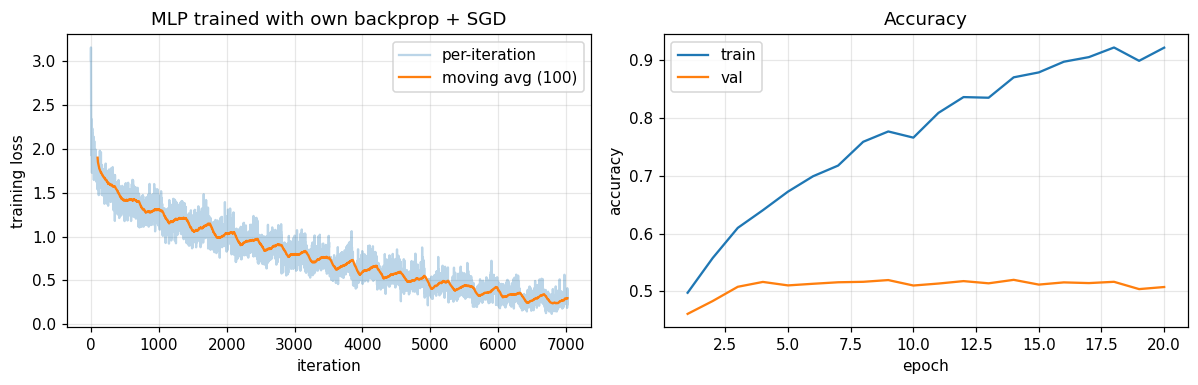

Final validation accuracy: 0.5076


In [ ]:
Xtr_f, Xva_f = Xtr.flatten(1), Xva.flatten(1)
set_seed()
mlp = MLP([3072, 512, 256, 10], act='relu', device=device)
EPOCHS_1C, LR_1C, BS_1C = 20, 0.05, 128
it_loss, va_hist, tr_hist = [], [], []
for e in range(EPOCHS_1C):
    perm = torch.randperm(len(Xtr_f), device=device)
    for b in range(len(perm) // BS_1C):
        idx = perm[b * BS_1C:(b + 1) * BS_1C]
        it_loss.append(mlp.loss(Xtr_f[idx], Ytr[idx]))
        mlp.backward()
        for L in mlp.linears():                       # plain SGD step
            L.W -= LR_1C * L.dW; L.b -= LR_1C * L.db
    acc = lambda X, Y: (mlp.forward(X).argmax(1) == Y).float().mean().item()
    va_hist.append(acc(Xva_f, Yva)); tr_hist.append(acc(Xtr_f, Ytr))
    print(f'epoch {e+1:2d} | train acc {tr_hist[-1]:.3f} | val acc {va_hist[-1]:.3f}')
it_loss = torch.stack(it_loss).cpu().numpy()

w = min(100, len(it_loss))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(it_loss, alpha=0.3, label='per-iteration'); ax[0].plot(np.arange(w - 1, len(it_loss)), np.convolve(it_loss, np.ones(w) / w, 'valid'), label=f'moving avg ({w})')
ax[0].set(xlabel='iteration', ylabel='training loss', title='MLP trained with own backprop + SGD'); ax[0].legend()
ax[1].plot(range(1, EPOCHS_1C + 1), tr_hist, label='train'); ax[1].plot(range(1, EPOCHS_1C + 1), va_hist, label='val')
ax[1].set(xlabel='epoch', ylabel='accuracy', title='Accuracy'); ax[1].legend()
plt.tight_layout(); plt.show()
print(f'Final validation accuracy: {va_hist[-1]:.4f}')

The training loss graph is quite noisy, which is due to the fact that we are using SGD, which introduces a stochastic variation in the gradient calculations. However, the overall trend shows that the training loss decreases as training progresses. The training accuracy has steadily increased, but the validation accuracy has reached a plateau at around ~ 50 %, suggesting potential overfitting of the data.

This growing training-validation gap is quite expected because the MLP used here has no spatial inductive bias, so it tries its best to memorize the dataset rather than learn spatial features, resulting in high training accuracy but relatively low validation accuracy.

## (d) gradient norms ( with a 10-layer MLP)
Width 256, 10 `Linear` layers, one batch of 256 images, gradient norm of each weight matrix (layer 1 = closest to the input). Log scale.
Sigmoid is paired with Xavier init (its natural choice), ReLU with He init; ReLU with a tiny $N(0,0.01^2)$ init is added to show that the initialisation matters as well.

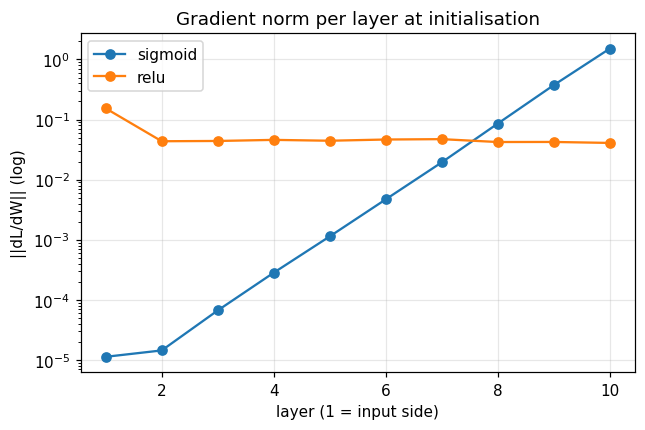

,sigmoid,relu
layer 1,1.14e-05,1.53e-01
layer 2,1.45e-05,4.36e-02
layer 3,6.70e-05,4.41e-02
layer 4,2.84e-04,4.59e-02
layer 5,1.14e-03,4.45e-02
layer 6,4.70e-03,4.66e-02
layer 7,1.94e-02,4.73e-02
layer 8,8.53e-02,4.23e-02
layer 9,3.72e-01,4.24e-02
layer 10,1.50e+00,4.09e-02


In [6]:
def layer_grad_norms(act, depth=10, width=256, n=256):
    set_seed()
    m = MLP([3072] + [width] * (depth - 1) + [10], act=act, device=device)
    m.loss(Xtr[:n].flatten(1), Ytr[:n]); m.backward()
    return [L.dW.norm().item() for L in m.linears()]

norms = {act: layer_grad_norms(act) for act in ('sigmoid', 'relu')}

plt.figure(figsize=(6.5, 4))
for k, v in norms.items():
    plt.semilogy(range(1, 11), v, 'o-', label=k)
plt.xlabel('layer (1 = input side)'); plt.ylabel('||dL/dW|| (log)')
plt.title('Gradient norm per layer at initialisation'); plt.legend(); plt.show()

display(pd.DataFrame(norms, index=[f'layer {i}' for i in range(1, 11)]).style.format('{:.2e}'))

- **Sigmoid:** $\sigma'(z) \leq 0.25$ for all values of $z$, meaning that each layer reduces the gradient significantly. Over 10 layers, this effect compounds, causing the gradient to vanish towards the input layers. Therefore, the gradient in layer 1 is much smaller than in layer 10.

- **ReLU:** $\mathrm{ReLU}'(z)$ is either 1 for active units or 0 otherwise, so around half of the units pass the gradient through unchanged. This results in a much slower gradient decay compared to sigmoid, with the gradient remaining more usable across the layers.

Therefore, the early layers of the sigmoid network receive almost no learning signal and train very slowly, while the ReLU network maintains stronger gradients. This is the main reason ReLU is preferred over sigmoid in deep networks.

---
# Task 2: Optimizers

## (a) SGD with momentum and Adam


In [7]:
class MySGD(Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for grp in self.param_groups:
            for p in grp['params']:
                if p.grad is None: continue
                d = p.grad
                if grp['weight_decay'] != 0: d = d + grp['weight_decay'] * p
                if grp['momentum'] != 0:
                    st = self.state[p]
                    if 'buf' not in st: st['buf'] = d.clone()
                    else: st['buf'].mul_(grp['momentum']).add_(d)
                    d = st['buf']
                p.add_(d, alpha=-grp['lr'])
        return loss

class MyAdam(Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad(): loss = closure()
        for grp in self.param_groups:
            b1, b2 = grp['betas']
            for p in grp['params']:
                if p.grad is None: continue
                d = p.grad
                if grp['weight_decay'] != 0: d = d + grp['weight_decay'] * p
                st = self.state[p]
                if not st:
                    st['t'] = 0; st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                st['t'] += 1; t = st['t']
                st['m'].mul_(b1).add_(d, alpha=1 - b1)
                st['v'].mul_(b2).addcmul_(d, d, value=1 - b2)
                m_hat = st['m'] / (1 - b1 ** t)                      # bias correction
                v_hat = st['v'] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(grp['eps']), value=-grp['lr'])
        return loss

In [8]:
def compare(make_mine, make_ref, steps=100):
    set_seed(1)
    net1 = nn.Sequential(nn.Linear(20, 32), nn.Tanh(), nn.Linear(32, 3)).double()
    net2 = copy.deepcopy(net1)
    o1, o2 = make_mine(net1.parameters()), make_ref(net2.parameters())
    x, y = torch.randn(64, 20, dtype=torch.float64), torch.randint(0, 3, (64,))
    for _ in range(steps):
        for n, o in ((net1, o1), (net2, o2)):
            o.zero_grad(); F.cross_entropy(n(x), y).backward(); o.step()
    diff = max((p - q).abs().max().item() for p, q in zip(net1.parameters(), net2.parameters()))
    return diff, all(torch.allclose(p, q, atol=1e-10) for p, q in zip(net1.parameters(), net2.parameters()))

tests = {
    'SGD (lr .1)':                          (lambda p: MySGD(p, lr=.1),                              lambda p: torch.optim.SGD(p, lr=.1)),
    'SGD momentum .9, wd 1e-3':             (lambda p: MySGD(p, lr=.05, momentum=.9, weight_decay=1e-3), lambda p: torch.optim.SGD(p, lr=.05, momentum=.9, weight_decay=1e-3)),
    'Adam (lr 1e-2)':                       (lambda p: MyAdam(p, lr=1e-2),                           lambda p: torch.optim.Adam(p, lr=1e-2)),
    'Adam (lr 1e-2, wd 1e-3, betas .8/.9)': (lambda p: MyAdam(p, lr=1e-2, betas=(.8, .9), weight_decay=1e-3), lambda p: torch.optim.Adam(p, lr=1e-2, betas=(.8, .9), weight_decay=1e-3)),
}
rows = [{'case': k, 'max |param diff| after 100 steps': (r := compare(*v))[0], 'allclose': r[1]} for k, v in tests.items()]
display(pd.DataFrame(rows).style.format({'max |param diff| after 100 steps': '{:.2e}'}))

,case,max |param diff| after 100 steps,allclose
0,SGD (lr .1),0.00e+00,True
1,"SGD momentum .9, wd 1e-3",2.22e-16,True
2,Adam (lr 1e-2),3.44e-15,True
3,"Adam (lr 1e-2, wd 1e-3, betas .8/.9)",6.00e-15,True


## (b) Trajectories on the ill-conditioned quadratic $f(x,y)=\tfrac12(x^2+50y^2)$

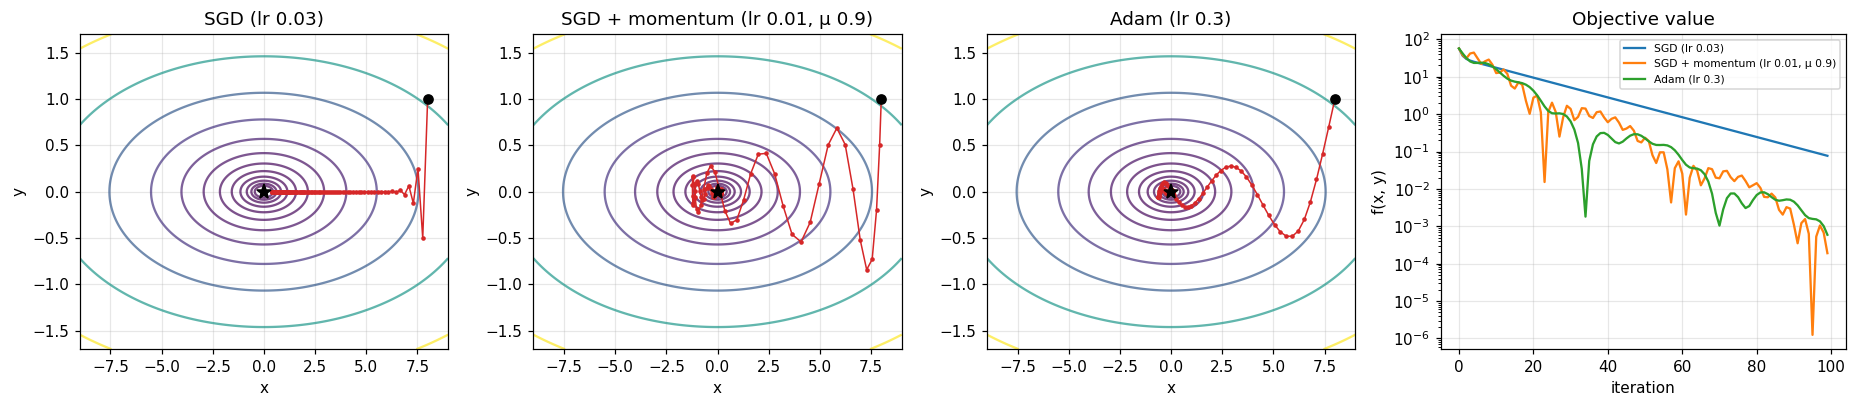

In [11]:
def run_quadratic(make_opt, start=(8., 1.), steps=100):
    w = torch.tensor(start, requires_grad=True); opt = make_opt([w])
    path, fs = [w.detach().numpy().copy()], []
    for _ in range(steps):
        opt.zero_grad(); f = 0.5 * (w[0] ** 2 + 50 * w[1] ** 2); f.backward(); fs.append(f.item()); opt.step()
        path.append(w.detach().numpy().copy())
    return np.array(path), fs

runs = {'SGD (lr 0.03)':                 run_quadratic(lambda p: MySGD(p, lr=0.03)),
        'SGD + momentum (lr 0.01, μ 0.9)': run_quadratic(lambda p: MySGD(p, lr=0.01, momentum=0.9)),
        'Adam (lr 0.3)':                  run_quadratic(lambda p: MyAdam(p, lr=0.3))}

xs, ys = np.linspace(-9, 9, 400), np.linspace(-1.7, 1.7, 400); XX, YY = np.meshgrid(xs, ys)
ZZ = 0.5 * (XX ** 2 + 50 * YY ** 2)
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8), gridspec_kw={'width_ratios': [1, 1, 1, 1.1]})
for a, (k, (path, fs)) in zip(ax[:3], runs.items()):
    a.contour(XX, YY, ZZ, levels=np.geomspace(0.1, 100, 12), cmap='viridis', alpha=0.7)
    a.plot(path[:, 0], path[:, 1], '.-', ms=4, lw=1, color='C3'); a.plot(*path[0], 'ko'); a.plot(0, 0, 'k*', ms=10)
    a.set(title=k, xlabel='x', ylabel='y', xlim=(-9, 9), ylim=(-1.7, 1.7))
for k, (path, fs) in runs.items(): ax[3].semilogy(fs, label=k)
ax[3].set(xlabel='iteration', ylabel='f(x, y)', title='Objective value'); ax[3].legend(fontsize=7)
plt.tight_layout(); plt.show()

The contours are very elongated, meaning that the function is steep in the $y$ direction and flat in the $x$ direction. The three optimizers respond to this differently.

**SGD:** After the first few steps, the path moves quickly towards $y=0$ and then runs almost straight along the $x$-axis. The learning rate has to stay small enough to remain stable in the steep $y$ direction, which makes the progress along the flatter $x$ direction very slow. This is visible in the objective plot, where the loss decreases steadily as a straight line on the log scale. SGD is also the furthest from the minimum after 100 iterations.

**SGD with momentum:**  The path is jagged and overshoots the minimum, but it is much faster overall. The velocity accumulates the gradients, so the consistent $x$-gradients add up and allow the optimizer to move much faster along the flat direction. The $y$-gradients keep changing sign, so they partly cancel out. However, due to the accumulated velocity, the optimizer does not stop at the minimum immediately. It overshoots, gets pulled back, and oscillates around the optimum. This explains the zig-zag path and the spikes in the objective curve. Momentum speeds up progress along the slow direction, but at the cost of oscillations.

**Adam:**  The path is smooth and curved, and the objective curve shows a fast initial drop with generally smoother behaviour. Adam divides each coordinate's update by the running scale of its gradient. Since the steep $y$ direction has larger gradients, its updates are scaled down, while the flatter $x$ direction has smaller gradients and receives relatively larger updates. This allows both coordinates to move at a more comparable pace, reducing the zig-zag caused by the different curvatures. Adam also uses running averages of the gradients, which helps smooth the updates. It may still overshoot slightly in the $y$ direction, but the adaptive scaling helps dampen the oscillations, allowing it to approach the minimum more smoothly than momentum.

**Summary:** SGD is stable but slow, momentum speeds up convergence but introduces oscillations, and Adam handles both directions more effectively by adapting the step size for each coordinate.

## (c) Optimizer sensitivity on a small CNN


In [15]:
def small_cnn(bn=False, p_drop=0.0):
    def blk(i, o):
        L = [nn.Conv2d(i, o, 3, padding=1, bias=not bn)]
        if bn: L.append(nn.BatchNorm2d(o))
        return L + [nn.ReLU(inplace=True), nn.MaxPool2d(2)]
    return nn.Sequential(*blk(3, 32), *blk(32, 64), *blk(64, 128), nn.Flatten(), nn.Dropout(p_drop), nn.Linear(128 * 16, 10))

GRID = {'SGD':          [3e-3, 3e-2, 3e-1],
        'SGD+momentum': [1e-3, 1e-2, 1e-1],      # momentum 0.9 -> effective lr ~10x larger
        'Adam':         [1e-4, 1e-3, 1e-2]}
def make_opt(name, params, lr):
    return {'SGD': lambda: MySGD(params, lr=lr), 'SGD+momentum': lambda: MySGD(params, lr=lr, momentum=0.9),
            'Adam': lambda: MyAdam(params, lr=lr)}[name]()

res2 = {}
for name, lrs in GRID.items():
    for lr in lrs:
        set_seed(); m = small_cnn().to(device)
        res2[(name, lr)] = train(m, make_opt(name, m.parameters(), lr), Xtr, Ytr, Xva, Yva, 10, name=f'{name} lr={lr:g}', verbose=False)
        h = res2[(name, lr)]; print(f'{name:13s} lr={lr:<7g} final val acc {h["val_acc"][-1]:.4f}  final train loss {h["train_loss"][-1]:.4f}' + ('  (diverged)' if h['diverged'] else ''))

SGD           lr=0.003   final val acc 0.4616  final train loss 1.4884


KeyboardInterrupt: 

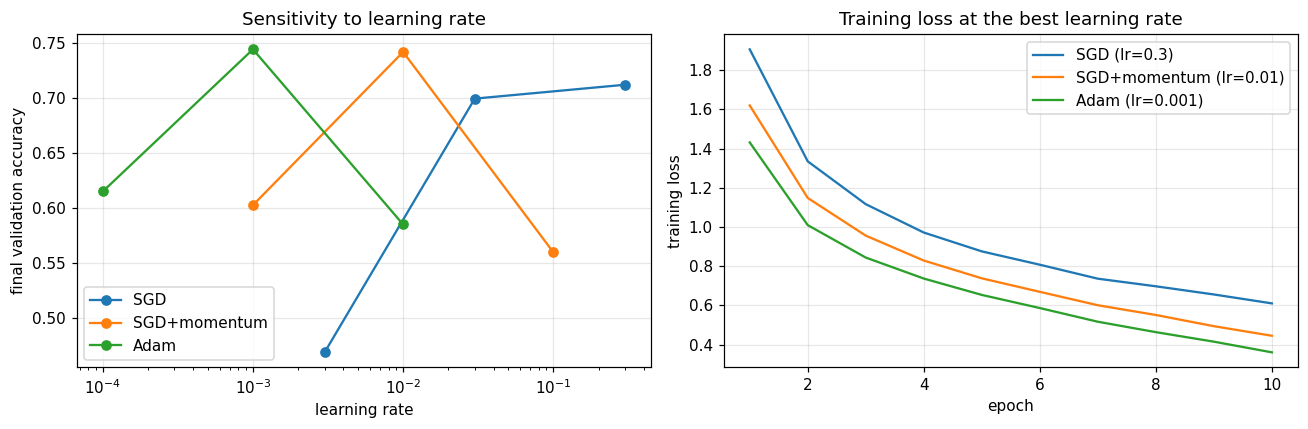

,optimizer,lr,val acc,train loss,diverged
0,SGD,0.003,0.4686,1.4880,False
1,SGD,0.03,0.6992,0.7827,False
2,SGD,0.3,0.7118,0.6100,False
3,SGD+momentum,0.001,0.6024,1.1048,False
4,SGD+momentum,0.01,0.7416,0.4449,False
5,SGD+momentum,0.1,0.5596,1.2130,False
6,Adam,0.0001,0.6148,1.0525,False
7,Adam,0.001,0.7440,0.3602,False
8,Adam,0.01,0.5848,1.1433,False


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
best = {}
for i, (name, lrs) in enumerate(GRID.items()):
    accs = [res2[(name, lr)]['val_acc'][-1] for lr in lrs]
    ax[0].semilogx(lrs, accs, 'o-', label=name, color=f'C{i}')
    best[name] = lrs[int(np.argmax(accs))]
    ax[1].plot(range(1, len(res2[(name, best[name])]['train_loss']) + 1), res2[(name, best[name])]['train_loss'], label=f'{name} (lr={best[name]:g})', color=f'C{i}')
ax[0].set(xlabel='learning rate', ylabel='final validation accuracy', title='Sensitivity to learning rate'); ax[0].legend()
ax[1].set(xlabel='epoch', ylabel='training loss', title='Training loss at the best learning rate'); ax[1].legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame([{'optimizer': k[0], 'lr': k[1], 'val acc': v['val_acc'][-1], 'train loss': v['train_loss'][-1], 'diverged': v['diverged']} for k, v in res2.items()]).style.format({'val acc': '{:.4f}', 'train loss': '{:.4f}', 'lr': '{:g}'}))

All three optimizers reach a similar peak validation accuracy of about $0.70$--$0.75$, but they respond differently to changes in the learning rate. Momentum and Adam both show a clear peak, where the accuracy drops on either side of the best learning rate. This suggests that a learning rate $10\times$ too small makes training too slow within 10 epochs, while a rate $10\times$ too large makes training unstable. Plain SGD performs poorly at the smallest learning rate and then stays almost flat at the two larger rates, suggesting that its best rate is at the edge of the tested range and the upper limit has not been found.

The best learning rate also falls in a different range for each optimizer. Momentum's best rate is about $30\times$ lower than that of plain SGD because, with $\mu = 0.9$, the accumulated velocity makes the effective step larger. Adam's best rate is $10^{-3}$, which is a commonly used default, since its updates are normalised based on the gradient scale and are therefore less sensitive to the scale of the gradients. This is a practical advantage of Adam, as a good learning rate is easier to choose, although its tolerance around the best rate is not necessarily wider in this experiment.

At their respective best learning rates, Adam achieves the lowest training loss, followed by momentum and then SGD. Adam and momentum also converge faster during the initial stages of training. However, since each experiment uses only 10 epochs and a single random seed, differences of less than $1\%$, such as those between Adam and momentum, may fall within the variation between runs and should not be considered conclusive.

---
# Task 3: Regularization and residual connections

## (a) Regularisation on 5 000 training images


In [ ]:
X5, Y5 = Xtr[:5000], Ytr[:5000]
CFG3A = {'baseline': {}, 'weight decay': dict(wd=5e-4), 'dropout': dict(p_drop=0.5), 'flip+crop': dict(flipcrop=True),
         'cutout': dict(cut=True), 'mixup': dict(mix=True),
         'all combined': dict(wd=5e-4, p_drop=0.5, flipcrop=True, cut=True, mix=True)}
EP3A = 60
res3a = {}
for name, c in CFG3A.items():
    set_seed(); model = small_cnn(bn=True, p_drop=c.get('p_drop', 0.0)).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, nesterov=True, weight_decay=c.get('wd', 0.0))
    spe = max(1, len(X5) // 128); sched = warmup_cosine(opt, EP3A * spe, spe)
    res3a[name] = train(model, opt, X5, Y5, Xva, Yva, EP3A, flipcrop=c.get('flipcrop', False), cut=c.get('cut', False),
                        mix=c.get('mix', False), sched=sched, eval_train=True, name=name, verbose=False)
    h = res3a[name]; print(f'{name:13s} train {h["train_acc"][-1]:.4f}  val {h["val_acc"][-1]:.4f}')

rows = [{'method': k, 'train acc': h['train_acc'][-1], 'val acc': h['val_acc'][-1], 'gap (train-val)': h['train_acc'][-1] - h['val_acc'][-1],
         'best val acc': max(h['val_acc'])} for k, h in res3a.items()]
display(pd.DataFrame(rows).style.format({c: '{:.4f}' for c in ['train acc', 'val acc', 'gap (train-val)', 'best val acc']}))

baseline      train 1.0000  val 0.6492
weight decay  train 1.0000  val 0.6596
dropout       train 1.0000  val 0.6730
flip+crop     train 0.9464  val 0.7350
cutout        train 1.0000  val 0.6698
mixup         train 1.0000  val 0.6218
all combined  train 0.7628  val 0.6778


,method,train acc,val acc,gap (train-val),best val acc
0,baseline,1.0000,0.6492,0.3508,0.6502
1,weight decay,1.0000,0.6596,0.3404,0.6616
2,dropout,1.0000,0.6730,0.3270,0.6756
3,flip+crop,0.9464,0.7350,0.2114,0.7364
4,cutout,1.0000,0.6698,0.3302,0.6744
5,mixup,1.0000,0.6218,0.3782,0.6304
6,all combined,0.7628,0.6778,0.0850,0.6794


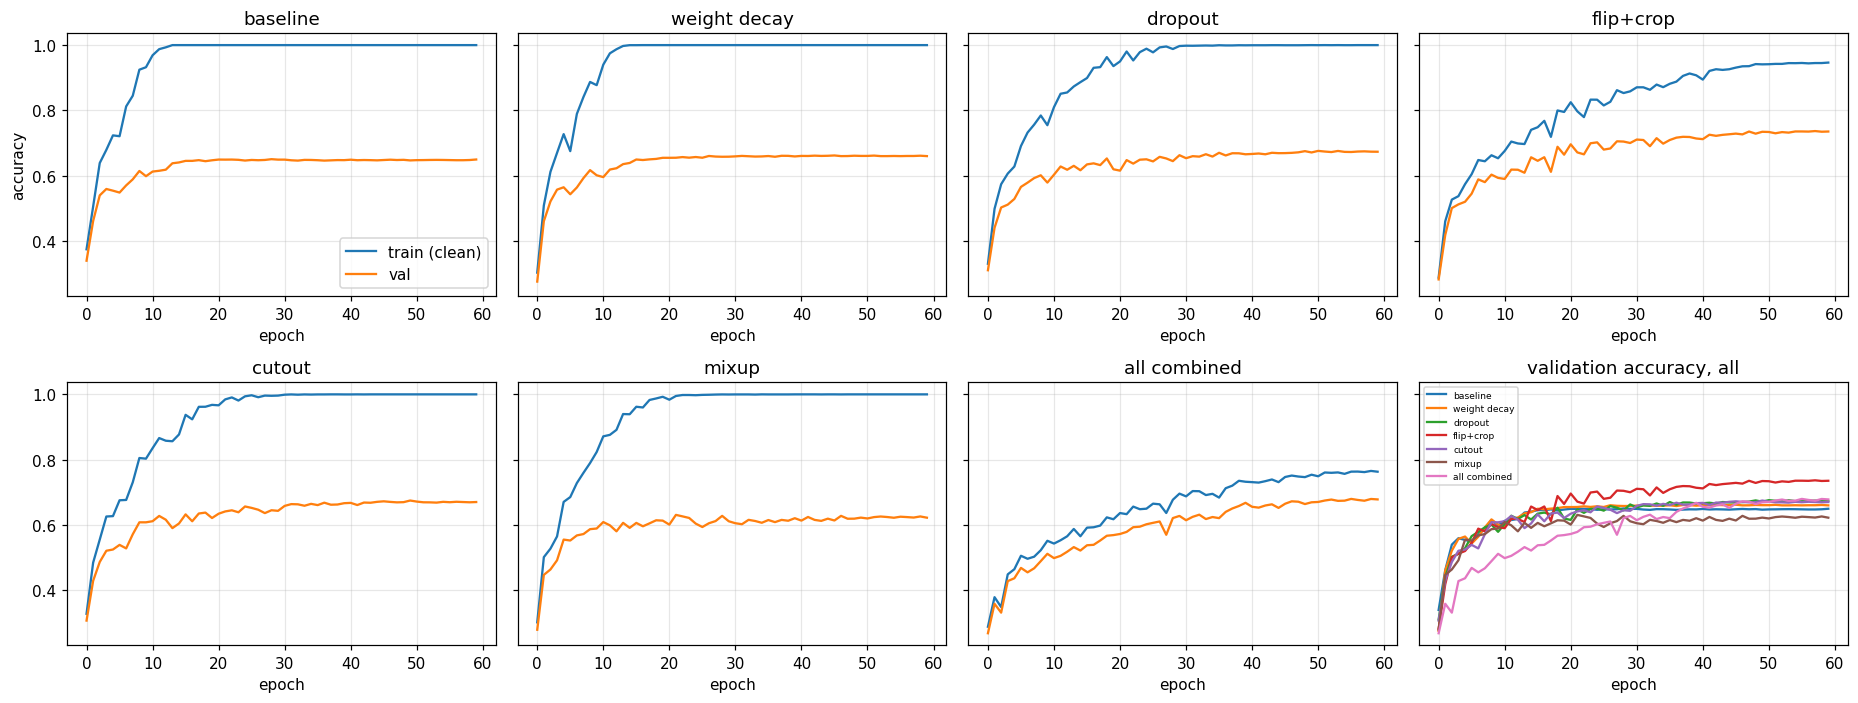

In [ ]:
fig, axs = plt.subplots(2, 4, figsize=(17, 6.5), sharey=True)
for a, (k, h) in zip(axs.flat, res3a.items()):
    a.plot(h['train_acc'], label='train (clean)'); a.plot(h['val_acc'], label='val'); a.set_title(k); a.set_xlabel('epoch')
axs.flat[0].set_ylabel('accuracy'); axs.flat[0].legend()
for k, h in res3a.items(): axs.flat[7].plot(h['val_acc'], label=k)
axs.flat[7].set_title('validation accuracy, all'); axs.flat[7].set_xlabel('epoch'); axs.flat[7].legend(fontsize=6)
plt.tight_layout(); plt.show()

The baseline model memorises the 5k training images, reaching 100\% training accuracy but only 64.9\% validation accuracy, giving a gap of 35.1 percentage points. The regularisers are compared against this baseline to see how well they improve generalisation.

**Single regularisers:**  Flip+crop is clearly the most effective, raising the validation accuracy by about 8.6 percentage points to 73.5\%. It is also the only single method that reduces the training accuracy, down to 94.6\%, shrinking the gap to 21.1 percentage points. This is because the input images are changed each epoch, making it harder for the network to simply memorise the 5k training images. Dropout and cutout also improve the validation accuracy by 2.4 and 2.1 percentage points, respectively. However, both still reach 100\% training accuracy, suggesting that the network continues to memorise the training set and the gap remains large at around 33 percentage points. Weight decay gives a small improvement of about 1.0 percentage point, which may be within the experimental noise. This is reasonable in a network with batch normalisation, since BN reduces the effect of weight scaling on the output, meaning weight decay can influence the effective learning rate rather than directly reducing the model's capacity. Mixup is the exception, as the validation accuracy drops to 62.2\%, about 2.7 percentage points below the baseline, while training accuracy remains at 100\%. It does not appear to help in this setup.

**Combined regularisation:**  Applying all the regularisers together gives the smallest gap of 8.5 percentage points, with a training accuracy of 76.3\%, suggesting that the network is no longer memorising the training set to the same extent. However, the validation accuracy is only 67.8\%, which is lower than the 73.5\% achieved using flip+crop alone. This suggests that the model is over-regularised for the given network and training budget. The low training accuracy indicates that it is still underfitting after 60 epochs, and the combined effects of mixup and cutout may make the task too difficult. Therefore, combining regularisers does not necessarily improve performance, and a longer training schedule may be needed for the combined model to benefit.



## (b) Plain vs. residual CIFAR networks of depth $6n+2$ (8, 20, 56)

In [ ]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.residual, self.down, self.padc = residual, (stride != 1 or cin != cout), (cout - cin) // 2
    def forward(self, x):
        out = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.residual:                                    # the ONLY difference between plain and residual nets
            sc = x
            if self.down: sc = F.pad(x[:, :, ::2, ::2], (0, 0, 0, 0, self.padc, self.padc))
            out = out + sc
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, n, widths=(16, 32, 64), residual=True, num_classes=10):
        super().__init__()
        self.conv1, self.bn1 = nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0])
        blocks, cin = [], widths[0]
        for i, w in enumerate(widths):
            for j in range(n):
                blocks.append(BasicBlock(cin, w, 2 if (i > 0 and j == 0) else 1, residual)); cin = w
        self.blocks, self.fc = nn.Sequential(*blocks), nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d): nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear): nn.init.kaiming_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x):
        x = self.blocks(F.relu(self.bn1(self.conv1(x))))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

for d in (8, 20, 56):
    n = (d - 2) // 6
    a, b = CifarNet(n, residual=False), CifarNet(n, residual=True)
    assert count_params(a) == count_params(b)
    print(f'depth {d} (n={n}): {count_params(a):,} params (plain and residual identical)')

depth 8 (n=1): 75,290 params (plain and residual identical)
depth 20 (n=3): 269,722 params (plain and residual identical)
depth 56 (n=9): 853,018 params (plain and residual identical)


In [ ]:
EP3B, res3b = 30, {}
for d in (8, 20, 56):
    for residual in (False, True):
        key = f"{'ResNet' if residual else 'Plain'}-{d}"
        set_seed(); model = CifarNet((d - 2) // 6, residual=residual).to(device)
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
        spe = len(Xtr) // 128; sched = warmup_cosine(opt, EP3B * spe, spe)
        t0 = time.time()
        res3b[key] = train(model, opt, Xtr, Ytr, Xva, Yva, EP3B, flipcrop=True, sched=sched, amp=True, name=key, verbose=True)
        print(f'--> {key}: {time.time()-t0:.0f}s, final train loss {res3b[key]["train_loss"][-1]:.4f}, val acc {res3b[key]["val_acc"][-1]:.4f}\n')

Plain-8 ep   1/30 | train loss 1.650 acc 0.394 | val loss 1.478 acc 0.468 | 2.4s
Plain-8 ep   4/30 | train loss 0.876 acc 0.692 | val loss 0.894 acc 0.683 | 2.4s
Plain-8 ep   7/30 | train loss 0.741 acc 0.744 | val loss 0.952 acc 0.673 | 2.4s
Plain-8 ep  10/30 | train loss 0.669 acc 0.768 | val loss 0.742 acc 0.749 | 2.4s
Plain-8 ep  13/30 | train loss 0.624 acc 0.785 | val loss 0.797 acc 0.732 | 2.3s


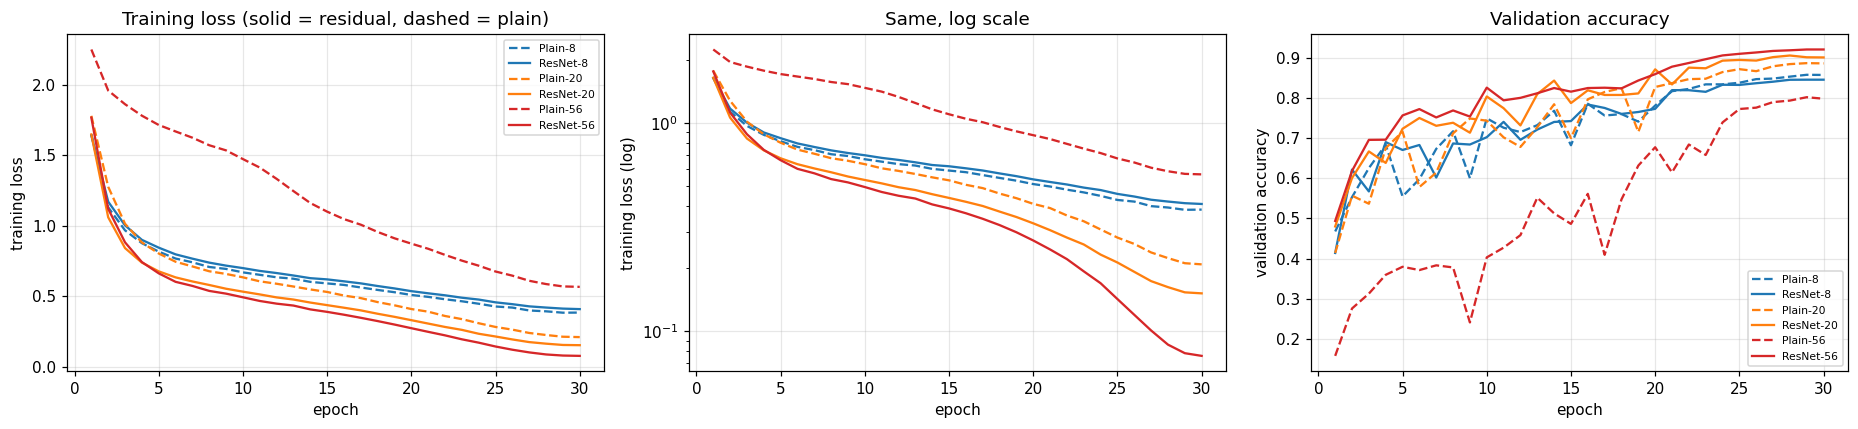

,model,depth,final train loss,min train loss,final val acc,diverged
0,Plain-8,8,0.3835,0.3827,0.8572,False
1,ResNet-8,8,0.4081,0.4081,0.8454,False
2,Plain-20,20,0.2094,0.2094,0.8860,False
3,ResNet-20,20,0.1519,0.1519,0.9008,False
4,Plain-56,56,0.5661,0.5661,0.7980,False
5,ResNet-56,56,0.0761,0.0761,0.9206,False


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
col = {8: 'C0', 20: 'C1', 56: 'C3'}
for k, h in res3b.items():
    d = int(k.split('-')[1]); ls = '-' if k.startswith('ResNet') else '--'
    ax[0].plot(range(1, len(h['train_loss']) + 1), h['train_loss'], ls, color=col[d], label=k)
    ax[1].plot(range(1, len(h['train_loss']) + 1), h['train_loss'], ls, color=col[d], label=k)
    ax[2].plot(range(1, len(h['val_acc']) + 1), h['val_acc'], ls, color=col[d], label=k)
ax[0].set(xlabel='epoch', ylabel='training loss', title='Training loss (solid = residual, dashed = plain)'); ax[0].legend(fontsize=7)
ax[1].set(xlabel='epoch', ylabel='training loss (log)', title='Same, log scale', yscale='log')
ax[2].set(xlabel='epoch', ylabel='validation accuracy', title='Validation accuracy'); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
display(pd.DataFrame([{'model': k, 'depth': int(k.split('-')[1]), 'final train loss': h['train_loss'][-1], 'min train loss': min(h['train_loss']),
                       'final val acc': h['val_acc'][-1], 'diverged': h['diverged']} for k, h in res3b.items()]).style.format({'final train loss': '{:.4f}', 'min train loss': '{:.4f}', 'final val acc': '{:.4f}'}))

The two network families behave differently as depth increases, even though each plain/residual pair has the same number of parameters and differs only in the shortcut connections.

**Plain networks (degradation) -** The final training loss is 0.383 at depth 8, 0.209 at depth 20 and 0.566 at depth 56. The 56-layer plain network has a training loss almost three times that of the 20-layer network, and it is even worse than the 8-layer network. A deeper network should theoretically be able to perform at least as well as a shallower one, since the extra layers could learn the identity mapping. Therefore, this is not a lack of model capacity but an optimisation problem, where the optimiser struggles to find a good solution for the deeper network within the same training budget. This is known as the *degradation problem*. It is also not simply overfitting, because the training loss itself is high, and the validation accuracy follows the same trend (79.8\% for plain-56, compared to 85.7\% for plain-8 and 88.6\% for plain-20).

**Residual networks -** The trend is the opposite, with training loss decreasing steadily as depth increases (0.408 $\rightarrow$ 0.152 $\rightarrow$ 0.076), while validation accuracy improves from 84.5\% to 90.1\% and 92.1\%. With the shortcut connection, each block computes $y=x+F(x)$, allowing it to learn a correction to the input rather than having to learn the complete mapping. This makes deeper networks easier to optimise. The shortcut also provides a direct path for the gradient to reach earlier layers, instead of passing only through a long chain of multiplications, reducing the vanishing-gradient problem discussed in Task 1(d).

**Shallow pairs -** At depth 8, the two families perform similarly, with plain-8 being slightly better (training loss 0.383 vs 0.408 and validation accuracy 85.7\% vs 84.5\%). This suggests that shallow networks are already relatively easy to optimise without shortcuts, so the residual connection does not provide a clear benefit at this depth. However, the difference could also be due to random seed variation, since each configuration was run only once. At depth 20, the residual network performs better (training loss 0.152 vs 0.209 and validation accuracy 90.1\% vs 88.6\%), while at depth 56, the difference becomes much larger (training loss 0.076 vs 0.566 and validation accuracy 92.1\% vs 79.8\%). Therefore, the benefit of shortcut connections becomes more significant as the network gets deeper.


---
# Task 4 (optional): Best CNN with ≤ 500k parameters and ≤ 20 epochs

In [ ]:
BASE = dict(n=3, widths=(20, 40, 80), residual=True, opt='sgd', lr=0.1, wd=5e-4, flipcrop=True, cut=True, ls=0.1)
EP4 = 20

def run_cfg(cfg, tag):
    set_seed(); model = CifarNet(cfg['n'], cfg['widths'], cfg['residual']).to(device)
    npar = count_params(model); assert npar <= 500_000, npar
    if cfg['opt'] == 'sgd': opt = torch.optim.SGD(model.parameters(), lr=cfg['lr'], momentum=0.9, nesterov=True, weight_decay=cfg['wd'])
    else:                   opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['wd'])
    spe = len(Xtr) // 128; sched = warmup_cosine(opt, EP4 * spe, spe)
    h = train(model, opt, Xtr, Ytr, Xva, Yva, EP4, flipcrop=cfg['flipcrop'], cut=cfg['cut'], label_smoothing=cfg['ls'],
              sched=sched, amp=True, name=tag, verbose=False)
    print(f'{tag:34s} params {npar:,} | final val acc {h["val_acc"][-1]:.4f} | best {max(h["val_acc"]):.4f}')
    return dict(cfg=cfg, hist=h, params=npar, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()})

# ---- 1) tune the peak learning rate on the validation split ----
sweep = {lr: run_cfg({**BASE, 'lr': lr}, f'lr={lr}') for lr in (0.05, 0.1, 0.2)}
best_lr = max(sweep, key=lambda lr: sweep[lr]['hist']['val_acc'][-1]); print('best lr:', best_lr)
FINAL = {**BASE, 'lr': best_lr}

/tmp/ipykernel_1014/2102008084.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched is not None: sched.step()


lr=0.05                            params 420,670 | final val acc 0.8798 | best 0.8798
lr=0.1                             params 420,670 | final val acc 0.8970 | best 0.8970
lr=0.2                             params 420,670 | final val acc 0.9006 | best 0.9006
best lr: 0.2


no shortcut (plain net)            params 420,670 | final val acc 0.8722 | best 0.8722


/tmp/ipykernel_1014/2102008084.py:80: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched is not None: sched.step()


no augmentation                    params 420,670 | final val acc 0.8710 | best 0.8722
no cutout                          params 420,670 | final val acc 0.9104 | best 0.9104
no weight decay                    params 420,670 | final val acc 0.8798 | best 0.8798
no label smoothing                 params 420,670 | final val acc 0.9010 | best 0.9016
AdamW instead of SGD (lr 3e-3)     params 420,670 | final val acc 0.8844 | best 0.8844


,variant,params,final val acc,best val acc,Δ vs full
0,full model (reference),"420,670",0.9006,0.9006,+0.0000
1,no shortcut (plain net),"420,670",0.8722,0.8722,-0.0284
2,no augmentation,"420,670",0.8710,0.8722,-0.0296
3,no cutout,"420,670",0.9104,0.9104,+0.0098
4,no weight decay,"420,670",0.8798,0.8798,-0.0208
5,no label smoothing,"420,670",0.9010,0.9016,+0.0004
6,AdamW instead of SGD (lr 3e-3),"420,670",0.8844,0.8844,-0.0162


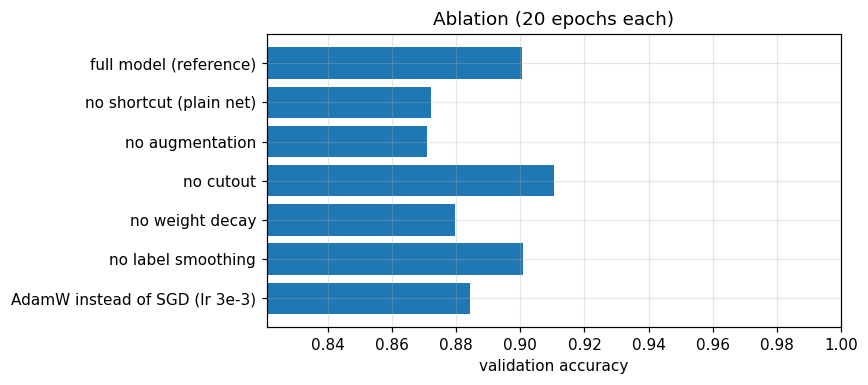

In [ ]:
# ---- 2) ablation: remove / change ONE design choice at a time (validation accuracy) ----
ABL = {'full model (reference)':          {},
       'no shortcut (plain net)':         dict(residual=False),
       'no augmentation':                 dict(flipcrop=False, cut=False),
       'no cutout':                       dict(cut=False),
       'no weight decay':                 dict(wd=0.0),
       'no label smoothing':              dict(ls=0.0),
       'AdamW instead of SGD (lr 3e-3)':  dict(opt='adamw', lr=3e-3, wd=5e-2)}
abl = {'full model (reference)': sweep[best_lr]}                      # identical config + seed -> reuse the run
for name, ch in ABL.items():
    if name not in abl: abl[name] = run_cfg({**FINAL, **ch}, name)
ref = abl['full model (reference)']['hist']['val_acc'][-1]
df = pd.DataFrame([{'variant': k, 'params': v['params'], 'final val acc': v['hist']['val_acc'][-1], 'best val acc': max(v['hist']['val_acc']),
                    'Δ vs full': v['hist']['val_acc'][-1] - ref} for k, v in abl.items()])
display(df.style.format({'final val acc': '{:.4f}', 'best val acc': '{:.4f}', 'Δ vs full': '{:+.4f}', 'params': '{:,}'}))
plt.figure(figsize=(8, 3.6)); plt.barh(df['variant'][::-1], df['final val acc'][::-1], color='C0'); plt.xlim(max(0, df['final val acc'].min() - 0.05), 1)
plt.xlabel('validation accuracy'); plt.title('Ablation (20 epochs each)'); plt.tight_layout(); plt.show()

Each row changes one design choice relative to the full model, which achieves 90.1\% validation accuracy. The changes can be ranked based on how much the validation accuracy drops when a component is removed or changed.

1. **Data augmentation and the shortcut (\(-3.0\) and \(-2.8\) percentage points):** These are the most important components and have a similar impact. Without augmentation, the 0.42 M-parameter network overfits the 45k training images more easily. Without the shortcut, the network becomes a plain 20-layer network, which is harder to optimise within only 20 epochs, consistent with the results in Task 3(b).

2. **Weight decay (\(-2.1\) percentage points):** Removing weight decay causes a fairly large drop in validation accuracy, showing that it is a useful regulariser within this training budget, even with batch normalisation.

3. **AdamW instead of SGD (\(-1.6\) percentage points):** With the settings tested, AdamW generalises worse than SGD with momentum. However, only one AdamW setting (\(\text{lr}=3\times10^{-3}\), weight decay \(=5\times10^{-2}\)) was tested, so this difference may also depend on the choice of hyperparameters.

4. **Label smoothing (\(+0.04\) percentage points):** Removing label smoothing has almost no effect on validation accuracy, and the difference is too small to be meaningful.

5. **Cutout (\(+1.0\) percentage point when removed):** Removing cutout slightly improves validation accuracy. With only 20 epochs, the network may still be underfitting rather than overfitting, so the additional noise from cutout makes training harder without providing a clear benefit. Since removing both augmentations (flip+crop and cutout) reduces accuracy by 3.0 percentage points, while removing cutout alone improves it by 1.0 point, flip+crop appears to account for most of the improvement.


Final model: 420,670 parameters, 20 epochs | val acc 0.9006 | TEST ACCURACY 0.8946


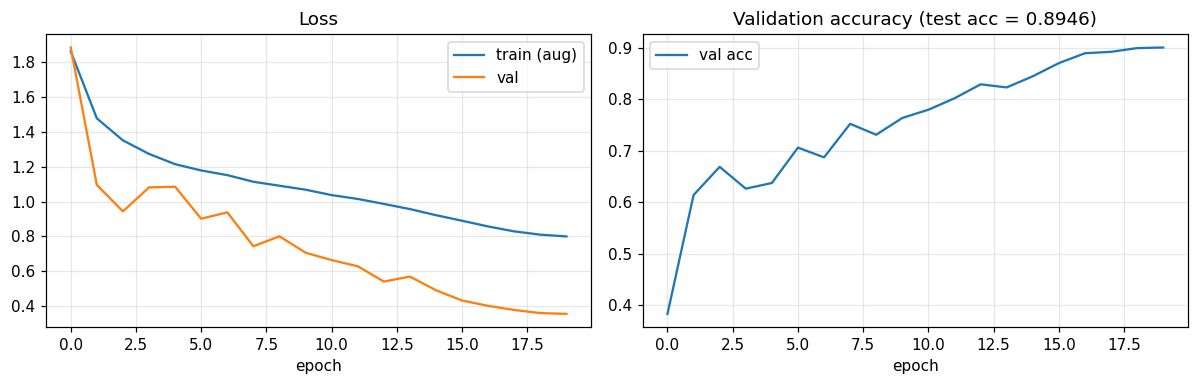

In [ ]:
# ---- 3) FINAL: evaluate the chosen model on the test set exactly ONCE ----
assert 'TEST_DONE' not in globals(), 'The test set has already been used once - do not re-evaluate!'
final = abl['full model (reference)']
net = CifarNet(FINAL['n'], FINAL['widths'], FINAL['residual']).to(device); net.load_state_dict(final['state'])
test_loss, test_acc = evaluate(net, Xte.to(device), Yte.to(device), amp=True); TEST_DONE = True
print(f'Final model: {final["params"]:,} parameters, {EP4} epochs | val acc {final["hist"]["val_acc"][-1]:.4f} | TEST ACCURACY {test_acc:.4f}')
h = final['hist']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h['train_loss'], label='train (aug)'); ax[0].plot(h['val_loss'], label='val'); ax[0].set(xlabel='epoch', title='Loss'); ax[0].legend()
ax[1].plot(h['val_acc'], label='val acc'); ax[1].set(xlabel='epoch', title=f'Validation accuracy (test acc = {test_acc:.4f})'); ax[1].legend()
plt.tight_layout(); plt.show()

**Summary:** The final model is a CIFAR-style ResNet-20 (3 stages, widths 20/40/80, parameter-free shortcuts and global average pooling) with **420,670 parameters**, which is below the 500k limit. It was trained for **20 epochs** using SGD with Nesterov momentum, a warm-up + cosine learning-rate schedule, weight decay, flip+crop and cutout augmentation, and label smoothing. The peak learning rate was selected using the validation split. The model achieved **90.06\% validation accuracy** and **89.46\% test accuracy**, with the test set evaluated once. The test accuracy is about 0.6 percentage points below the validation accuracy, which is a relatively small difference and could be due to normal sampling variation and the use of the validation set for selecting the learning rate. This difference alone does not indicate a problem with overfitting to the validation set.

**What mattered most:** The ablation results showed that data augmentation (\(-3.0\) percentage points when removed) and the residual shortcut (\(-2.8\) percentage points) had the largest impact, followed by weight decay (\(-2.1\) percentage points). Using AdamW instead of SGD with momentum reduced accuracy by 1.6 percentage points. Label smoothing had almost no measurable effect, while removing cutout slightly improved validation accuracy by 1.0 percentage point. This suggests that, with only 20 epochs, the additional regularisation from cutout may make training more difficult without providing a clear benefit. However, since each experiment was run with a single seed, only the larger differences can be considered reasonably convincing.

**With more budget, I would try:**

- Training for more epochs (e.g., 100--200), where stronger regularisation such as cutout and mixup may become more useful.
- Repeating the main comparisons with several random seeds to distinguish actual effects from random variation, especially for cutout and label smoothing.
- Increasing the network width or adding more blocks while staying within the parameter budget.
- Training the final model on all 50k images (training + validation) with the hyperparameters fixed, and using test-time augmentation such as horizontal-flip averaging.